In [151]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [152]:
class Value:

    def __init__(self,data,_children=(),_op='',label =''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        
        out = Value(self.data + other.data, (self,other),'+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out

    def __mul__(self,other, ):
        other = other if isinstance(other,Value) else Value(other)

        out = Value(self.data * other.data, (self,other),'*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __pow__(self,other):
        assert isinstance(other,(int,float)),"only supporting int/float powers for now"
        out = Value(self.data**other, (self, ),f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward

        return out

    def __rmul__(self,other):

        return self * other 

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        
        return self + (-other)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ),'tanh')

        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self, ),'exp')

        def _backward():
            self.grad = out.data * out.grad
            
        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()



In [153]:
from graphviz import Digraph

def trace(root):

    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = ձախից աջ
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        dot.node(name=uid, label=f"{{ %s | data %.4f | grad %.4f}}" % (n.label, n.data,n.grad), shape='record')

        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)


    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

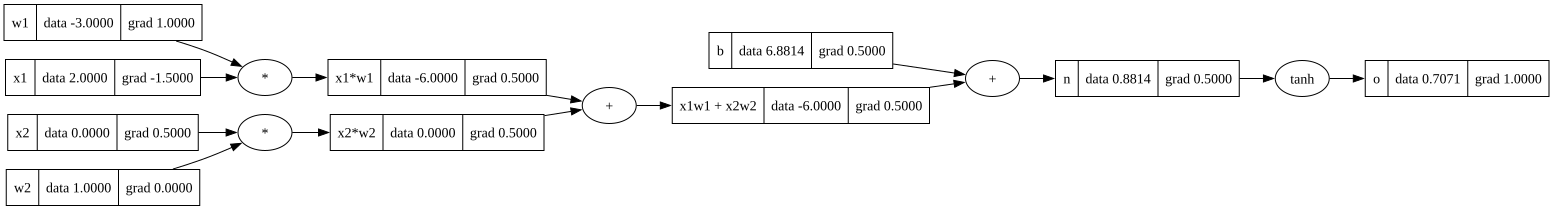

In [154]:
#inputs x1 ,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
#weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
#bias of the neuron
b = Value(6.8813735870295432,label='b')
#x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b;n.label ='n'
o = n.tanh(); o.label = 'o'
o.backward()
draw_dot(o)

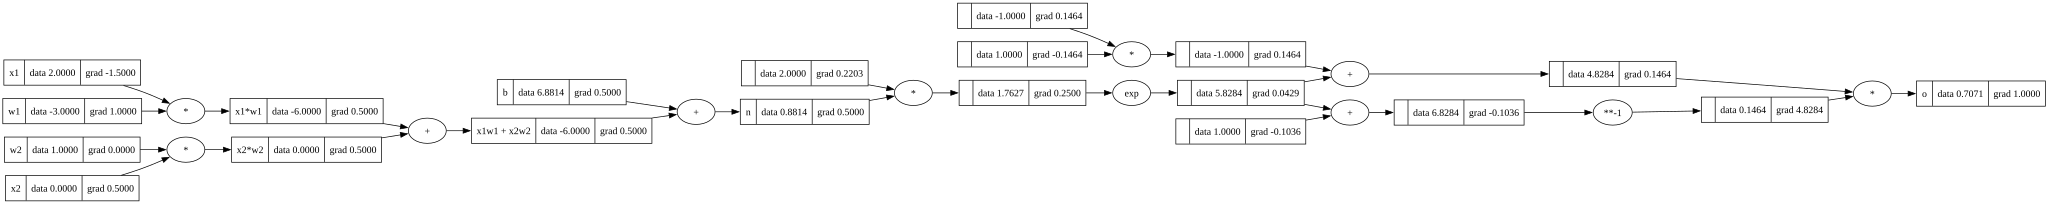

In [155]:
#inputs x1 ,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
#weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
#bias of the neuron
b = Value(6.8813735870295432,label='b')
#x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b;n.label ='n'
#----

e = (2*n).exp()

o = (e -1)/(e + 1)
#----
o.label = 'o'
o.backward()
draw_dot(o)

In [156]:
import torch

x1 = torch.Tensor([2.0]).double() ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double() ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ; b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('—')
print('x2', x2.grad.item())
print('w2', w2.grad.item())

print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
—
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [303]:
import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):
        # w * x + b
        act = sum((wi * xi for wi, xi in zip(self.w,x)),self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

    

class Layer:

    def __init__(self,nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        prams = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            prams.extend(ps)

        return prams




class MLP:

    def __init__(self,nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]


    def __call__(self,x):
        for layer in self.layers:
            x = layer(x)

        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]




In [317]:
n = MLP(3,[4,4,1])


In [318]:
n.parameters()

[Value(data=-0.3794924867155087),
 Value(data=0.8401313152879522),
 Value(data=-0.16506103348873125),
 Value(data=-0.4098295716600566),
 Value(data=-0.2315777103648613),
 Value(data=-0.0693168181062993),
 Value(data=-0.07365549472037403),
 Value(data=0.8969945389245537),
 Value(data=-0.2162795940808626),
 Value(data=-0.13077985697631433),
 Value(data=-0.3836531267836667),
 Value(data=-0.8459614665584367),
 Value(data=-0.9396042102927917),
 Value(data=0.3963532458859764),
 Value(data=0.3332993838141838),
 Value(data=0.36934321314952334),
 Value(data=-0.6763748200528832),
 Value(data=-0.33109248471013886),
 Value(data=0.6476808260739426),
 Value(data=-0.7098705800788621),
 Value(data=0.041587274990932954),
 Value(data=0.4547005359575953),
 Value(data=-0.16249892298076785),
 Value(data=0.30868079385633007),
 Value(data=0.03963170433600216),
 Value(data=0.15514516077561957),
 Value(data=-0.3787744940172053),
 Value(data=-0.230910506567797),
 Value(data=-0.7865019862139129),
 Value(data=0.5

In [319]:
# draw_dot(n(x))

In [320]:
xs =[
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

In [331]:
for k in range(100):
    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

    #backward pass
    for p in n.parameters():
        p.grad = 0
    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.1 * p.grad

    print(k, loss.data)

0 0.0011676259512650917
1 0.0011612981998271924
2 0.0011550363206317867
3 0.0011488393044279518
4 0.0011427061623241238
5 0.0011366359252796595
6 0.0011306276436116405
7 0.0011246803865161302
8 0.0011187932416036096
9 0.0011129653144479493
10 0.0011071957281486079
11 0.0011014836229054912
12 0.0010958281556060485
13 0.0010902284994243104
14 0.0010846838434313364
15 0.0010791933922168068
16 0.00107375636552127
17 0.0010683719978788278
18 0.0010630395382697957
19 0.001057758249783168
20 0.0010525274092883015
21 0.0010473463071159254
22 0.0010422142467476799
23 0.0010371305445144529
24 0.001032094529302715
25 0.0010271055422689944
26 0.001022162936562056
27 0.0010172660770525082
28 0.0010124143400697335
29 0.001007607113145861
30 0.0010028437947664833
31 0.0009981237941280013
32 0.0009934465309014602
33 0.000988811435002404
34 0.0009842179463669502
35 0.0009796655147335741
36 0.0009751535994305484
37 0.0009706816691689576
38 0.0009662492018409438
39 0.0009618556843231619
40 0.000957500612

In [332]:
ypred

[Value(data=0.9901226896143326),
 Value(data=-0.9889088033180062),
 Value(data=-0.985337513193423),
 Value(data=0.9821468125861025)]